# Custom CNN

In [ ]:
# 1) dataset.zip upload
import os, glob
if not os.path.isdir("/content/Tumour"):
    from google.colab import files
    up = files.upload()
    z = sorted(glob.glob("/content/*.zip"))[0]
    os.system(f'unzip -q -o "{z}" -d /content/')
print(os.listdir("/content/Tumour"))

In [ ]:
# 2) Imports + data
import os, json, time, shutil, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support
from sklearn.utils.class_weight import compute_class_weight

SEED = 42; tf.keras.utils.set_random_seed(SEED)
DATA = "/content/Tumour"; IMG = (224, 224); BS = 32
EPOCHS = int(os.environ.get("BT_EPOCHS", 30)); SMOKE = os.environ.get("BT_SMOKE")
if os.environ.get("BT_DATA"): DATA = os.environ["BT_DATA"]

def load(split, shuffle):
    return keras.utils.image_dataset_from_directory(f"{DATA}/{split}", image_size=IMG, batch_size=BS,
                                                   label_mode="int", shuffle=shuffle, seed=SEED)
train_ds, val_ds, test_ds = load("train", True), load("valid", False), load("test", False)
class_names = train_ds.class_names
print("Classes:", class_names)
y_train = np.concatenate([y.numpy() for _, y in train_ds])
cw = compute_class_weight("balanced", classes=np.arange(len(class_names)), y=y_train)
class_weights = dict(enumerate(cw)); print("class weights:", {class_names[i]: round(w, 2) for i, w in class_weights.items()})
if SMOKE: train_ds, val_ds, test_ds = train_ds.take(2), val_ds.take(2), test_ds.take(2)
AUTOTUNE = tf.data.AUTOTUNE
train_ds, val_ds, test_ds = [d.prefetch(AUTOTUNE) for d in (train_ds, val_ds, test_ds)]

In [ ]:

augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
], name="augmentation")

def build_custom_cnn(num_classes):
    inp = keras.Input(shape=(*IMG, 3), name="image")
    x = layers.Rescaling(1.0 / 255, name="normalize_0_1")(inp)
    x = augment(x)
    for f in [32, 64, 128, 256]:
        for _ in range(2):
            x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
            x = layers.BatchNormalization(momentum=0.9)(x)
            x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(0.2)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.BatchNormalization(momentum=0.9)(x)
    x = layers.Dropout(0.4)(x)
    out = layers.Dense(num_classes, activation="softmax", name="probs")(x)
    return keras.Model(inp, out, name="CustomCNN")

model = build_custom_cnn(len(class_names))
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
os.makedirs("models", exist_ok=True)
cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
       keras.callbacks.ModelCheckpoint("models/CustomCNN.h5", monitor="val_loss", save_best_only=True),
       keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=3, min_lr=1e-6)]
t0 = time.time()
hist = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, class_weight=class_weights, callbacks=cbs)
print(f"Training time: {(time.time()-t0)/60:.1f} min")

Epoch 1/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 402ms/step - accuracy: 0.6083 - loss: 1.0605

53/53 ━━━━━━━━━━━━━━━━━━━━ 39s 437ms/step - accuracy: 0.6578 - loss: 0.9627 - val_accuracy: 0.7131 - val_loss: 0.7582 - learning_rate: 0.0010
Epoch 2/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 0s 310ms/step - accuracy: 0.7018 - loss: 0.8494

53/53 ━━━━━━━━━━━━━━━━━━━━ 18s 335ms/step - accuracy: 0.7074 - loss: 0.8291 - val_accuracy: 0.7709 - val_loss: 0.6694 - learning_rate: 0.0010
Epoch 3/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 18s 337ms/step - accuracy: 0.7410 - loss: 0.7441 - val_accuracy: 0.2570 - val_loss: 3.9426 - learning_rate: 0.0010
Epoch 4/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 18s 333ms/step - accuracy: 0.7381 - loss: 0.7591 - val_accuracy: 0.6355 - val_loss: 0.8557 - learning_rate: 0.0010
Epoch 5/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 18s 337ms/step - accuracy: 0.7546 - loss: 0.6838 - val_accuracy: 0.6036 - val_loss: 1.0507 - learning_rate: 0.0010
Epoch 6/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 18s 337ms/step - accuracy: 0.7717 - loss: 0.6255 - val_accuracy: 0.6972 - val_loss: 0.7701 - learning_rate: 3.0000e-04
Epoch 7/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 21s 343ms/step - accuracy: 0.7888 - loss: 0.5942 - val_accuracy: 0.7032 - val_loss: 0.7964 - learning_rate: 3.0000e-04
Epoch 8/30
53/53 ━━━━━━━━━━━━━━━━━━━━ 18s 339ms/step - accuracy: 0.7776 - loss: 0.613

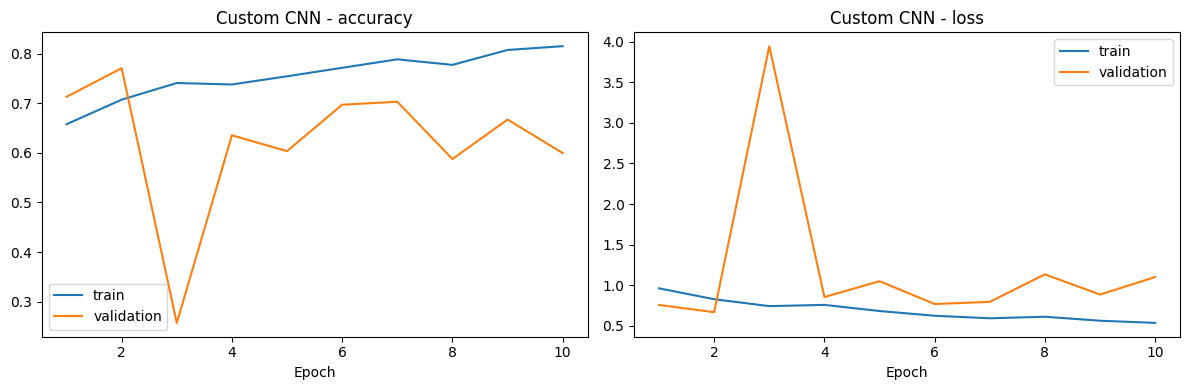

In [ ]:
# 4) Training curves
h = hist.history; ep = range(1, len(h["loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, k in zip(ax, ["accuracy", "loss"]):
    a.plot(ep, h[k], label="train"); a.plot(ep, h["val_" + k], label="validation"); a.set_title("Custom CNN - " + k); a.set_xlabel("Epoch"); a.legend()
plt.tight_layout(); plt.show()

Test accuracy: 0.7398 | precision 0.7420 | recall 0.7503 | F1 0.7300 | 5.2 ms/image
Predicted class counts: {'glioma': np.int64(75), 'meningioma': np.int64(38), 'no_tumor': np.int64(64), 'pituitary': np.int64(69)}
              precision    recall  f1-score   support

      glioma     0.8133    0.7625    0.7871        80
  meningioma     0.7895    0.4762    0.5941        63
    no_tumor     0.6406    0.8367    0.7257        49
   pituitary     0.7246    0.9259    0.8130        54

    accuracy                         0.7398       246
   macro avg     0.7420    0.7503    0.7300       246
weighted avg     0.7534    0.7398    0.7311       246



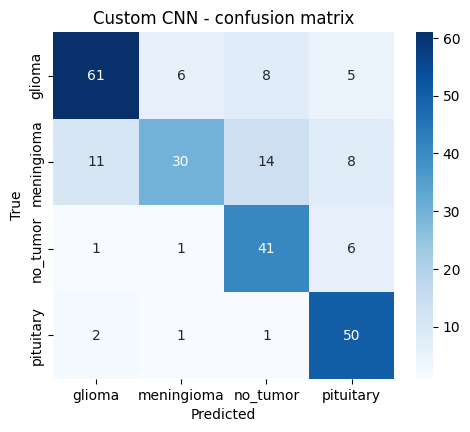

File size: 15.1 MB | Params: 1.24 M


In [ ]:
# 5) Evaluate the SAVED best model on the test set
best = keras.models.load_model("models/CustomCNN.h5", compile=False)
t0 = time.time()
probs = best.predict(test_ds, verbose=0)
ms = (time.time() - t0) / len(probs) * 1000
y_true = np.concatenate([y.numpy() for _, y in test_ds]); y_pred = probs.argmax(1)
p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
print(f"Test accuracy: {accuracy_score(y_true, y_pred):.4f} | precision {p:.4f} | recall {r:.4f} | F1 {f:.4f} | {ms:.1f} ms/image")
print("Predicted class counts:", dict(zip(class_names, np.bincount(y_pred, minlength=len(class_names)))))
print(classification_report(y_true, y_pred, labels=list(range(len(class_names))), target_names=class_names, digits=4, zero_division=0))
cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))
plt.figure(figsize=(5.5, 4.5)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Custom CNN - confusion matrix"); plt.show()
print("File size: %.1f MB | Params: %.2f M" % (os.path.getsize("models/CustomCNN.h5") / 1e6, best.count_params() / 1e6))

In [ ]:
# 6) Download the new CustomCNN.h5 (put it in your local models/ folder, replace the old one)
if not SMOKE:
    from google.colab import files
    files.download("models/CustomCNN.h5")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>